### Importar historico de preços de ativos Forex

### Imports

In [2]:
import MetaTrader5 as mt5
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model      import LinearRegression
from statsmodels.tsa.stattools import adfuller

In [3]:
# Initializing MT5 connection 
#if not mt5.initialize(path="D:\\programs\\metatrader\\modal\\terminal64.exe"): # producao modal
#if not mt5.initialize(path="D:\\programs\\metatrader\\desen\\terminal64.exe", portable=True): # desen modal
# if not mt5.initialize(path="D:\\programs\\metatrader\\modal\\terminal64.exe", portable=True): # produ modal
if not mt5.initialize(path="D:\\programs\\mt5\\desen\\terminal64.exe", portable=True): # desen forex
    print("initialize() failed, error code =",mt5.last_error())
    quit()
    
print("MetaTrader5 terminal_info():", mt5.terminal_info())
print("MetaTrader5 version()      :", mt5.version()      )

MetaTrader5 terminal_info(): TerminalInfo(community_account=True, community_connection=True, connected=True, dlls_allowed=False, trade_allowed=False, tradeapi_disabled=False, email_enabled=False, ftp_enabled=False, notifications_enabled=False, mqid=False, build=6198, maxbars=100000, codepage=1252, ping_last=215229, community_balance=9.995246, retransmission=0.25449117871294036, company='MetaQuotes Software Corp.', name='MetaTrader 5', language='Portuguese (Brazil)', path='D:\\programs\\mt5\\desen', data_path='D:\\programs\\mt5\\desen', commondata_path='C:\\Users\\marco\\AppData\\Roaming\\MetaQuotes\\Terminal\\Common')
MetaTrader5 version()      : (500, 6198, '15 Sep 2026')


In [4]:
#obtendo os dados do símbolos na corretora...
def get_symbol_info():
    # obtemos todos os símbolos
    symbols=mt5.symbols_get()
    qtd_symb = len(symbols)
    count=0

    vals = []
    cols = []
    for s in symbols:
        count+=1
        #if count > 3: break
        #print("Importando {} {}/{}".format(s.name, count, qtd_symb))

        # exibimos as propriedades do símbolo como uma lista
        symbol_info_dict = s._asdict()
        if count==1: 
            cols = symbol_info_dict.keys()
            print(cols)
        vals.append(symbol_info_dict.values() )
    
    # criando coluna extra com a categoria...
    dfs = pd.DataFrame(data=vals,columns=cols)
    dfs["categ"] = dfs["path"].str.split("\\").str.get(0)
    
    # eliminando a coluna com path...
    dfs.drop(["path","page","session_volume","session_interest"], axis=1, inplace=True)
    
    for col in dfs.columns:
        if dfs[col].max() == dfs[col].min():
            print("Elimanado a coluna ", col, " tipo:", dfs[col].dtype, " max:", dfs[col].max(), " min:", dfs[col].min())
            dfs.drop([col], axis=1, inplace=True)
    
    #for col in dfs.columns:
    #    print(dfs[col].dtype)
    
    return dfs


In [44]:
# !pip install openpyxl

In [6]:
# obtendo os dados de simbolos na corretora...
dfs = get_symbol_info()
dfs.head()

# salvamos as propriedades dos simbolos em uma planilha
dfs.to_excel("symbols_forex.xlsx")
#dfs = pd.read_excel("symbols_b3.xlsx")

dict_keys(['custom', 'chart_mode', 'select', 'visible', 'session_deals', 'session_buy_orders', 'session_sell_orders', 'volume', 'volumehigh', 'volumelow', 'time', 'digits', 'spread', 'spread_float', 'ticks_bookdepth', 'trade_calc_mode', 'trade_mode', 'start_time', 'expiration_time', 'trade_stops_level', 'trade_freeze_level', 'trade_exemode', 'swap_mode', 'swap_rollover3days', 'margin_hedged_use_leg', 'expiration_mode', 'filling_mode', 'order_mode', 'order_gtc_mode', 'option_mode', 'option_right', 'bid', 'bidhigh', 'bidlow', 'ask', 'askhigh', 'asklow', 'last', 'lasthigh', 'lastlow', 'volume_real', 'volumehigh_real', 'volumelow_real', 'option_strike', 'point', 'trade_tick_value', 'trade_tick_value_profit', 'trade_tick_value_loss', 'trade_tick_size', 'trade_contract_size', 'trade_accrued_interest', 'trade_face_value', 'trade_liquidity_rate', 'volume_min', 'volume_max', 'volume_step', 'volume_limit', 'swap_long', 'swap_short', 'margin_initial', 'margin_maintenance', 'session_volume', 'sess

In [7]:
# obtendo os filtros em uma planilha da B3 com os simbolos cujo volume de trades no dia eh maior que 10mil.
#dffilter = pd.read_excel("TradeInformationConsolidatedFile.xlsx")
#dffilter = pd.read_csv("TradeInformationConsolidatedFile.csv",sep=";")

# simbolos que serao efetivamente processados
#dffilter = pd.read_excel("filtro.xlsx",sep=";") #filtro.xls contem os simbolos que queremos importar
#dfs = dfs[ dfs["name"].isin(dffilter["ticker"]) ] 

# simbolos que serao efetivamente processados
# dffilter = pd.read_excel("filtro-20220709-acoes.xlsx") #filtro.xls contem os simbolos que queremos importar
# dfs = dfs[ dfs["name"].isin(dffilter["TckrSymb"]) ] 

# simbolos que tem o valor ask
dfs = dfs[ dfs["ask"]>0 ]
habilitados = ['EURUSD','GBPUSD','AUDUSD','NZDUSD','EURCHF','NZDCHF','AUDCHF','EURGBP','AUDCAD','GBPCHF','CADCHF','AUDNZD','EURCAD','NZDCAD','EURNZD','AUDJPY','NZDJPY','GBPNZD','GBPCAD','EURJPY','CADJPY','EURAUD','GBPJPY','CHFJPY','GBPAUD','USDCHF','USDJPY','USDCAD']

# tirando de dfs, os simbolos que nao estao habilitados...
dfs = dfs[dfs["name"].isin(habilitados)]
print(dfs)


     chart_mode  select  visible        time  digits  spread  spread_float  \
0             0    True     True  1789541502       5       4          True   
1             0    True     True  1789541500       5       4          True   
5             0    True     True  1789541502       3       6          True   
7             0    True     True  1789541501       5       4          True   
12            0    True     True  1789541502       5       1          True   
37            0    True     True  1789541498       5       4          True   
56            0    True     True  1789541502       5       0          True   
73            0    True     True  1789541502       5       1          True   
89            0    True     True  1789541504       5       1          True   
98            0    True     True  1789541502       5       0          True   
99            0    True     True  1789541504       5       1          True   
109           0    True     True  1789541500       3       2    

In [9]:
from oslib2.fonte_de_dados_mt import get_all_ticker_data
from datetime import datetime
dfa = get_all_ticker_data(dfs["name"], datetime.now().year,datetime.now().month,datetime.now().day,1000, timeframe=mt5.TIMEFRAME_H1,verbose=True)
dfa


Obtendo cotacoes de  AUDCAD 1 de 12 ...
Obtendo cotacoes de  AUDCHF 2 de 12 ...
Obtendo cotacoes de  AUDJPY 3 de 12 ...
Obtendo cotacoes de  AUDNZD 4 de 12 ...
Obtendo cotacoes de  AUDUSD 5 de 12 ...
Obtendo cotacoes de  EURCAD 6 de 12 ...
Obtendo cotacoes de  EURUSD 7 de 12 ...
Obtendo cotacoes de  GBPUSD 8 de 12 ...
Obtendo cotacoes de  NZDUSD 9 de 12 ...
Obtendo cotacoes de  USDCAD 10 de 12 ...
Obtendo cotacoes de  USDCHF 11 de 12 ...
Obtendo cotacoes de  USDJPY 12 de 12 ...


,time,open,high,low,close,tick_volume,spread,real_volume,ticker
0,2026-07-20 09:00:00,0.97941,0.97947,0.97862,0.97918,6627,0,0,AUDCAD
1,2026-07-20 10:00:00,0.97918,0.98122,0.97897,0.98101,8449,0,0,AUDCAD
2,2026-07-20 11:00:00,0.98101,0.98166,0.98097,0.98159,5895,0,0,AUDCAD
3,2026-07-20 12:00:00,0.98159,0.98217,0.98106,0.98189,5996,0,0,AUDCAD
4,2026-07-20 13:00:00,0.98189,0.98289,0.98173,0.98271,4410,0,0,AUDCAD
...,...,...,...,...,...,...,...,...,...
995,2026-09-15 20:00:00,155.06800,155.19300,155.03200,155.16500,5287,0,0,USDJPY
996,2026-09-15 21:00:00,155.16500,155.20900,155.07700,155.09100,5827,0,0,USDJPY
997,2026-09-15 22:00:00,155.09100,155.14200,155.06300,155.12600,4918,0,0,USDJPY
998,2026-09-15 23:00:00,155.12600,155.15000,155.09800,155.10500,2990,0,0,USDJPY


In [10]:
#dfa.to_csv("dfa_h1_b3.csv")
dfa.to_excel("dfa_h1_forex.xlsx")

In [11]:
#dfo = dfa.pivot(index='time', columns='ticker', values='open')
dfc = dfa.pivot(index='time', columns='ticker', values='close').dropna()
dfv = dfa.pivot(index='time', columns='ticker', values='tick_volume').dropna()

dfc.to_excel("dfc.xlsx")
dfc


ticker,AUDCAD,AUDCHF,AUDJPY,AUDNZD,AUDUSD,EURCAD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY
time,,,,,,,,,,,,
2026-07-20 09:00:00,0.97918,0.56433,113.521,1.19529,0.69897,1.60194,1.14352,1.34585,0.58475,1.40096,0.80739,162.411
2026-07-20 10:00:00,0.98101,0.56451,113.658,1.19507,0.70002,1.60379,1.14442,1.34764,0.58576,1.40151,0.80642,162.363
2026-07-20 11:00:00,0.98159,0.56492,113.664,1.19573,0.70003,1.60397,1.14391,1.34698,0.58542,1.40229,0.80702,162.370
2026-07-20 12:00:00,0.98189,0.56552,113.669,1.19646,0.69986,1.60364,1.14300,1.34631,0.58491,1.40307,0.80805,162.418
2026-07-20 13:00:00,0.98271,0.56607,113.791,1.19713,0.70067,1.60326,1.14311,1.34680,0.58526,1.40260,0.80792,162.403
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-15 20:00:00,0.99178,0.58396,110.620,1.23822,0.71292,1.60504,1.15374,1.34746,0.57575,1.39122,0.81910,155.165
2026-09-15 21:00:00,0.99241,0.58372,110.604,1.23847,0.71316,1.60628,1.15427,1.34805,0.57583,1.39166,0.81851,155.091
2026-09-15 22:00:00,0.99242,0.58387,110.617,1.23844,0.71308,1.60619,1.15408,1.34741,0.57578,1.39180,0.81880,155.126


<Axes: xlabel='time'>

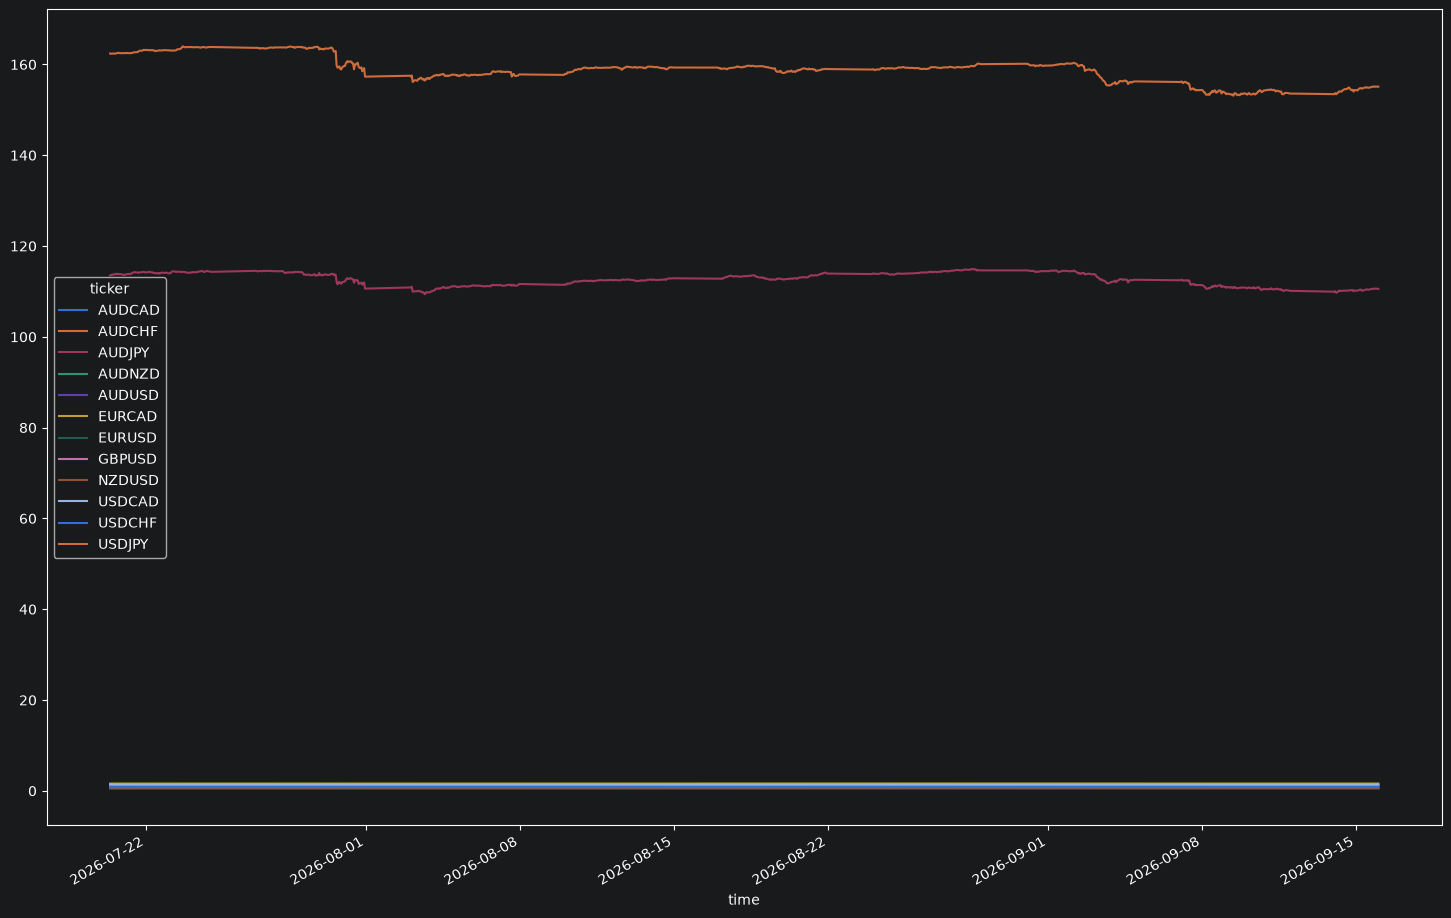

In [12]:
dfc.plot(figsize=(18,12))

In [13]:
# normalizando...
dfcn = dfc - dfc.mean()
dfcn

ticker,AUDCAD,AUDCHF,AUDJPY,AUDNZD,AUDUSD,EURCAD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY
time,,,,,,,,,,,,
2026-07-20 09:00:00,-0.00908,-0.010564,0.780581,-0.013758,-0.010585,-0.007306,-0.011851,-0.003566,-0.002111,0.007945,-0.002874,3.496833
2026-07-20 10:00:00,-0.00725,-0.010384,0.917581,-0.013978,-0.009535,-0.005456,-0.010951,-0.001776,-0.001101,0.008495,-0.003844,3.448833
2026-07-20 11:00:00,-0.00667,-0.009974,0.923581,-0.013318,-0.009525,-0.005276,-0.011461,-0.002436,-0.001441,0.009275,-0.003244,3.455833
2026-07-20 12:00:00,-0.00637,-0.009374,0.928581,-0.012588,-0.009695,-0.005606,-0.012371,-0.003106,-0.001951,0.010055,-0.002214,3.503833
2026-07-20 13:00:00,-0.00555,-0.008824,1.050581,-0.011918,-0.008885,-0.005986,-0.012261,-0.002616,-0.001601,0.009585,-0.002344,3.488833
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-15 20:00:00,0.00352,0.009066,-2.120419,0.029172,0.003365,-0.004206,-0.001631,-0.001956,-0.011111,-0.001795,0.008836,-3.749167
2026-09-15 21:00:00,0.00415,0.008826,-2.136419,0.029422,0.003605,-0.002966,-0.001101,-0.001366,-0.011031,-0.001355,0.008246,-3.823167
2026-09-15 22:00:00,0.00416,0.008976,-2.123419,0.029392,0.003525,-0.003056,-0.001291,-0.002006,-0.011081,-0.001215,0.008536,-3.788167


<Axes: xlabel='time'>

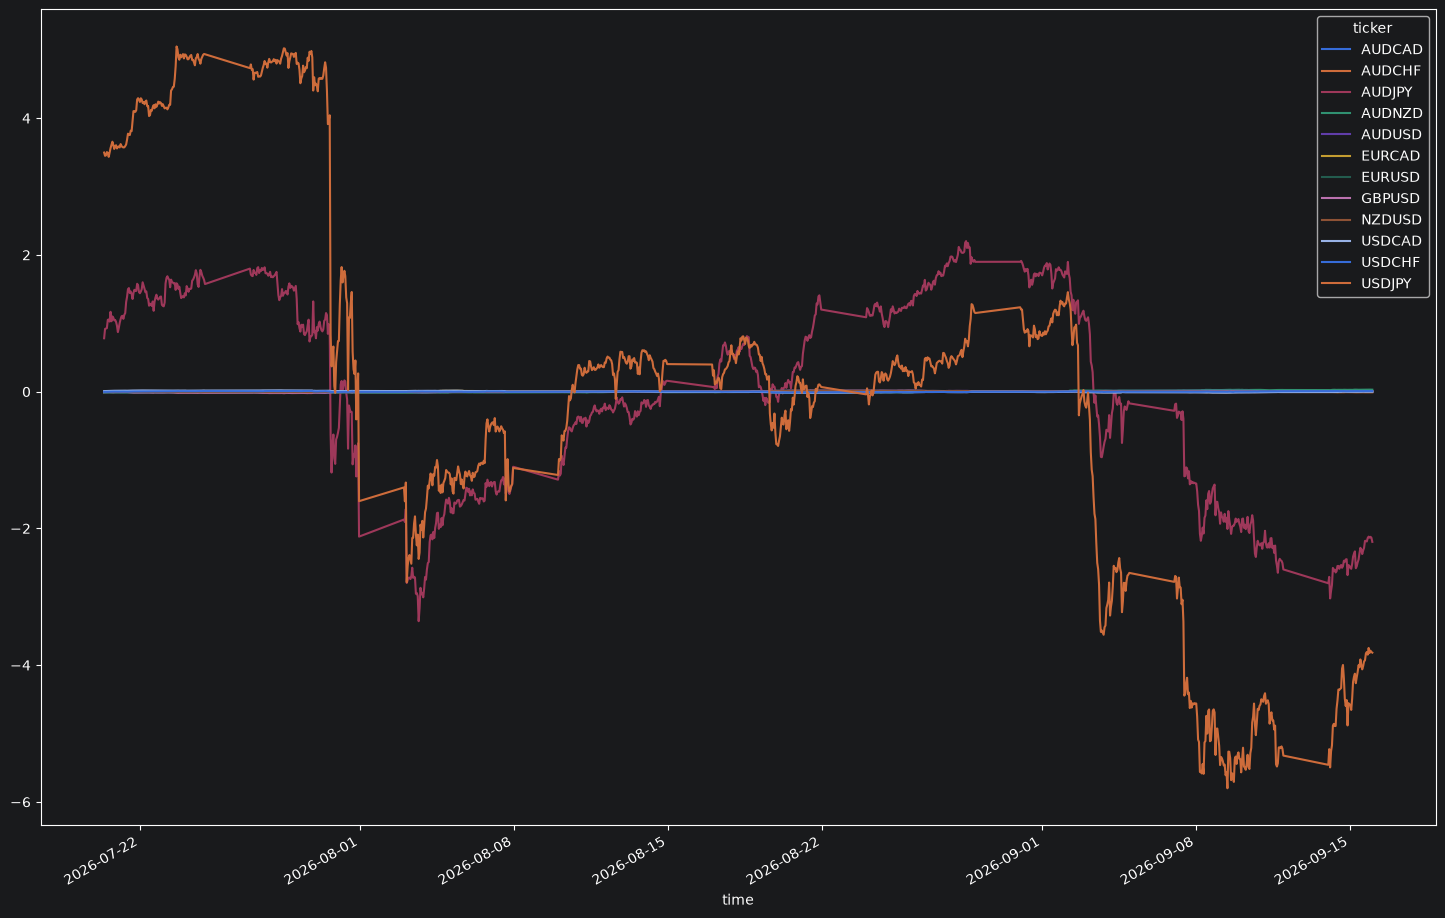

In [14]:
dfcn.plot(figsize=(18,12))

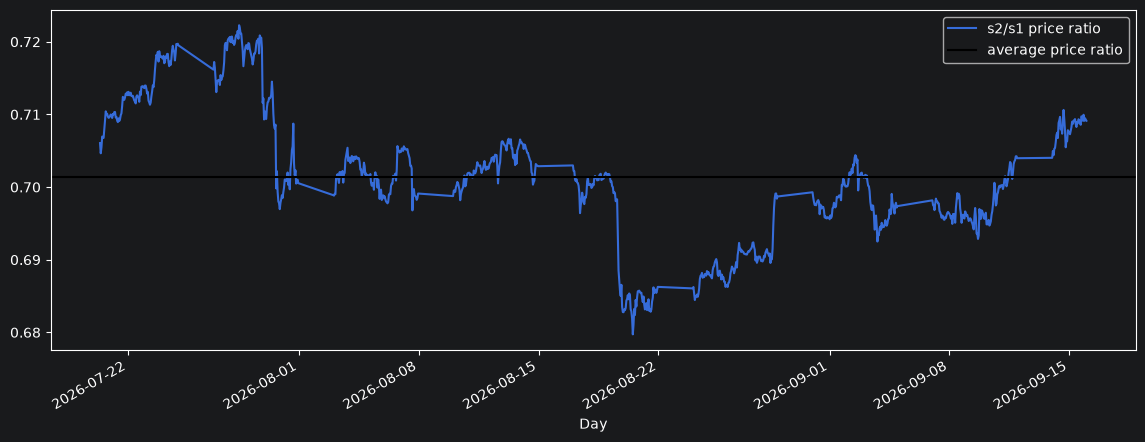

average price ratio 0.7014


In [15]:
s1 = dfc.EURUSD # dfc.BOVA11
s2 = dfc.USDCHF # dfc.WINQ22
price_ratio = s2/s1
price_ratio.plot(figsize=(14,5)) 
plt.axhline(price_ratio.mean(), color='black') 
plt.xlabel('Day')
plt.legend(['s2/s1 price ratio', 'average price ratio'])
plt.show()
print(f"average price ratio {price_ratio.mean():.4f}")

## Calculate hedge ratio with regression

## Linear Regression

Note that the LinearRegression().fit() expects 2D numpy arrays.  Since s1 and s2 are pandas series, we can use Series.values to get the values as a numpy array. Since these are 1D arrays, we can use numpy.reshape(-1,1) to make these 1000 row by 1 column 2 dimensional arrays


Observe que LinearRegression().fit() espera matrizes numpy 2D. Como s1 e s2 são séries pandas, podemos usar Series.values para obter os valores como uma matriz numpy. Como esses são arrays 1D, podemos usar numpy.reshape (-1,1) para tornar esses arrays bidimensionais de 1000 linhas por 1 coluna.

In [16]:
s1.values.reshape(-1,1).shape

(1000, 1)

In [17]:
lr = LinearRegression()
lr.fit(s1.values.reshape(-1, 1), s2.values.reshape(-1, 1))

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-0.4]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1.28]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[0.28]


In [18]:
hedge_ratio = lr.coef_[0][0]
hedge_ratio

np.float64(-0.40305002815060925)

In [19]:
intercept = lr.intercept_[0]
intercept

np.float64(1.275936559586393)

In [20]:
print(f"hedge ratio from regression is {hedge_ratio:.4f}, intercept is {intercept:.4f}")

hedge ratio from regression is -0.4031, intercept is 1.2759


 ## Question
 Do you think we'll need the intercept when calculating the spread?  Why or why not?
 
 Você acha que precisaremos da interceptação ao calcular o spread? Por que ou por que não?

## Calculate the spread

In [21]:
spread = s2 - s1 * hedge_ratio

In [23]:
print(f"Average spread is {spread.mean()}")

Average spread is 1.275936559586393


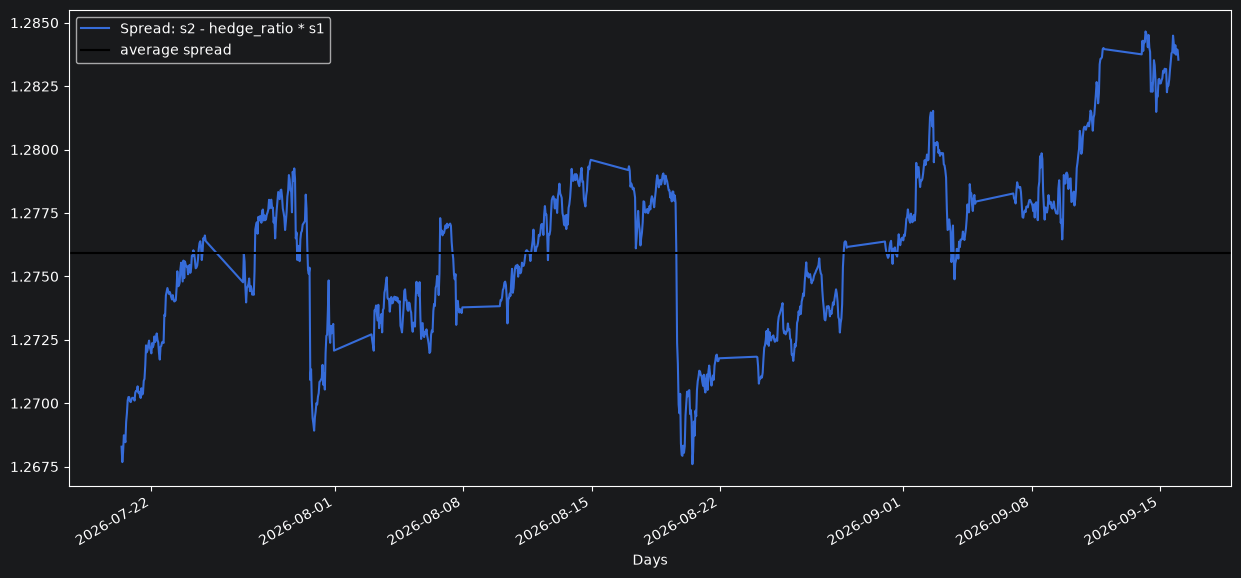

In [24]:
spread.plot(figsize=(15,7)) 
plt.axhline(spread.mean(), color='black') 
plt.xlabel('Days')
plt.legend(['Spread: s2 - hedge_ratio * s1', 'average spread'])
plt.show()

In [31]:
print(spread)

time
2026-07-15 09:00:00    1.217911
2026-07-15 10:00:00    1.218168
2026-07-15 11:00:00    1.218554
2026-07-15 12:00:00    1.219140
2026-07-15 13:00:00    1.218984
                         ...   
2026-09-10 20:00:00    1.227977
2026-09-10 21:00:00    1.228093
2026-09-10 22:00:00    1.228078
2026-09-10 23:00:00    1.227982
2026-09-11 00:00:00    1.228124
Length: 1000, dtype: float64


## Let's see what we get if we include the intercept of the regression

Vamos ver o que temos se incluirmos o intercepto da regressão

In [25]:
spread_with_intercept = s2 - (s1 * hedge_ratio + intercept)
print(f"Average spread with intercept included is {spread_with_intercept.mean()}")

Average spread with intercept included is 9.636735853746359e-17


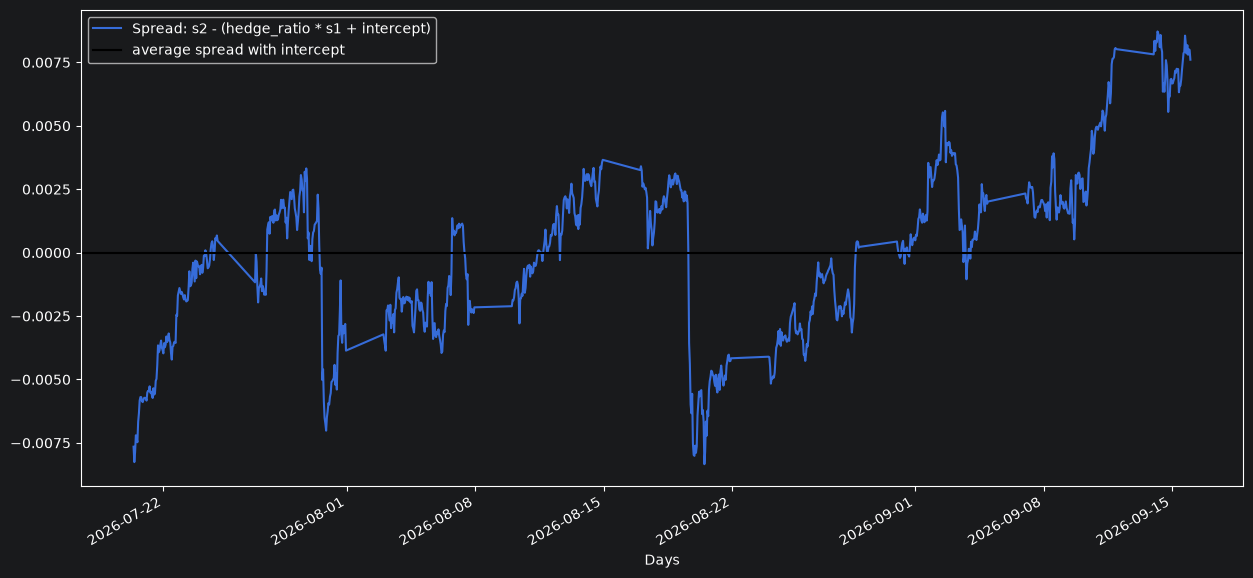

In [26]:
spread_with_intercept.plot(figsize=(15,7)) 
plt.axhline(spread_with_intercept.mean(), color='black') 
plt.xlabel('Days')
plt.legend(['Spread: s2 - (hedge_ratio * s1 + intercept)', 'average spread with intercept'])
plt.show()

## Quiz
### Check if spread is stationary using Augmented Dickey Fuller Test

The [adfuller](http://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html) function is part of the statsmodel library.

```
adfuller(x, maxlag=None, regression='c', autolag='AIC', store=False, regresults=False)[source]

adf (float) – Test statistic
pvalue (float) – p-value
...
```

In [38]:
def is_spread_stationary(spread, p_level=0.05):
    """
    spread: obtained from linear combination of two series with a hedge ratio
    p_level: level of significance required to reject null hypothesis of non-stationarity
    
    returns:
        True if spread can be considered stationary
        False otherwise
    """
    #TODO: use the adfuller function to check the spread
    adf_result = adfuller(spread)
    
    #get the p-value
    pvalue = adf_result[1]
    
    if pvalue <= p_level:
        print(f"pvalue {pvalue:.12f} is <= {p_level}, assume spread is stationary")
        return True
    else:
        print(f"pvalue {pvalue:.12f} is > {p_level}, assume spread is not stationary")
        return False
    
#quiz_tests.test_is_spread_stationary(is_spread_stationary)

In [39]:
#analisar_long_short(dfc,"AERI3","ABEV3")

In [40]:
# Try out your function
print(f"Are the two series candidates for pairs trading? {is_spread_stationary(spread_with_intercept)}")

pvalue 0.163896759755 is > 0.05, assume spread is not stationary
Are the two series candidates for pairs trading? False


C:\Users\marco\AppData\Local\Temp\ipykernel_17608\1967547339.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread)


1. construa uma função () que recebe 2 series de precos e retorna o p-valor da razao entre as duas series.
2. 

In [42]:
def calc_edge_spread(s1,s2):
    #s1.values.reshape(-1,1).shape
    lr = LinearRegression()
    lr.fit(s1.values.reshape(-1,1),s2.values.reshape(-1,1))
    hedge_ratio = lr.coef_[0][0]
    intercept = lr.intercept_[0]
    spread = s2 - (s1 * hedge_ratio + intercept)
    return spread, intercept, hedge_ratio
            

In [43]:
# retorna o ultimo item do vetor
def get_ultimo(vetor):
    return vetor[ vetor.shape[0]-1 ]

In [44]:
def generate_long_short_candidates(dfc):
    # IN
    # dfc: DataFrame
    #   precos de fechamento por data e ativo
    #
    # OUT
    # dfls: DataFrame
    #   cada linha é um par de ativos com seu resultado do seu teste de estacionariedade
    #
    long_short = []
    for name1,data1 in dfc.dropna().items():
        print("Testando",name1, "...")
        for name2,data2 in dfc.dropna().items():

            if name1 != name2:
                # calculando o edge spread...
                spread,intercept,hedge_ratio = calc_edge_spread(data1,data2)
                #spread = data1/data2

                # calculando a estacionariedade do spread...
                adf_result = adfuller(spread)
                adf    = adf_result[0]
                pvalue = adf_result[1]

                # mantendo log na tela durante a execução...
                if pvalue <= 0.05:
                    long_short.append( [ name1,name2,adf,pvalue,intercept,hedge_ratio,spread.std(), get_ultimo(spread) ] )
                    #print(name1, name2, adf, pvalue)

    return pd.DataFrame(long_short, columns=['ticker1','ticker2','adf','pvalue','intercept','hedge_ratio','std','spread_atual' ])


In [45]:
long_short = generate_long_short_candidates(dfc)

Testando AUDCAD ...


C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread)
C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread)
C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adf

Testando AUDCHF ...


C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread)
C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread)
C:\Users\marco\AppData\Local\Temp\ipykernel_17608\3300275423.py:21: FutureWarning: adf

KeyError: 999

In [35]:
#dfc.plot(figsize=(14,6))
#long_short.to_csv  ("long_short_b3_m1.csv")
#long_short.to_excel("long_short_b3_m1.xlsx")
long_short.to_excel("pairs_candidate.xlsx")

NameError: name 'long_short' is not defined

In [46]:
def plot_symbols(dfc,str1,str2,shift1=1,shift2=1):
    s1 = dfc[str1]*shift1
    s2 = dfc[str2]*shift2
    s1.name = str1
    s2.name = str2
    pd.concat([s1, s2], axis=1).plot(figsize=(15,4))
    plt.show()

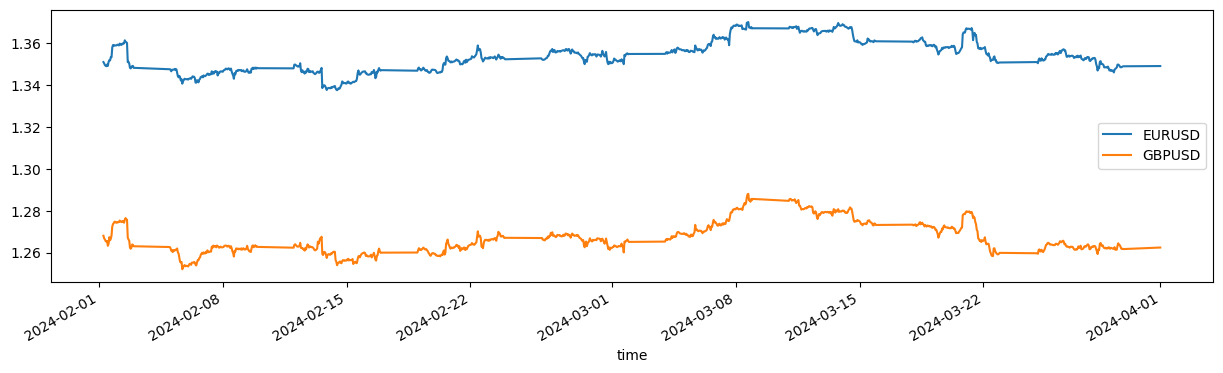

In [59]:
plot_symbols(dfc,"EURUSD","GBPUSD",1.25,1)

In [60]:
def plot_spread(spread,ativo1,ativo2):
    
    mean = spread.mean()
    std  = spread.std()
    zscore = ( ( spread - mean )/ std )
    
    print("std:",std)

    spread.name = "spread"
    zscore.name = "zscore"
    #pd.concat([spread, zscore], axis=1).plot(figsize=(14,5))
    spread.plot(figsize=(15,4))

    plt.axhline(mean  , color='black') 
    plt.axhline(std   , color='blue' ) 
    plt.axhline(-std  , color='blue' ) 
    plt.axhline(std*2   , color='red' ) 
    plt.axhline(-std*2  , color='red' ) 
    plt.xlabel('Days')
    #plt.legend([f'Spread: {ativo2} - hedge_ratio * {ativo1}', 'zscore','average spread','std','-std'])
    plt.legend([f'Spread: {ativo2} - hedge_ratio * {ativo1}','average spread','std','-std'])
    plt.show()

    #zscore.plot(figsize=(15,4))
    #plt.axhline( zscore.mean() , color='black') 
    #plt.axhline( zscore.std()  , color='blue' ) 
    #plt.axhline(-zscore.std()  , color='blue' ) 
    #plt.axhline( zscore.std()*2  , color='red' ) 
    #plt.axhline(-zscore.std()*2  , color='red' ) 
    #plt.legend(['zscore'])
    #plt.show()


In [61]:
def analisar_long_short(dfc,ativo1,ativo2, shift1=1,shift2=1):
    spread,intercept,hedge_ratio = calc_edge_spread( dfc[ativo1],dfc[ativo2] )
    plot_symbols(dfc,ativo1,ativo2,hedge_ratio,shift2)
    plot_spread(spread,ativo1,ativo2)
    coint = is_spread_stationary(spread)
    if coint:
        print(f"{ativo1} e {ativo2} são cointegrados. hedge_ratio:{hedge_ratio}")
    else:
        print(f"{ativo1} e {ativo2} NÃO são cointegrados.")


In [62]:
def analisar_long_short2(ativo1,ativo2,ano,mes,dia,qtd,timeframe=mt5.TIMEFRAME_M15,verbose=True):
    
    #obtendo os dados na corretora...
    df1=get_all_ticker_data([ativo1,ativo2], ano,mes,dia,qtd, timeframe,verbose)
    
    #organizando para ficar com indice por data e duas colunas cada uma com o preco de fechamento de um ativo...
    df1c = df1.pivot(index='time', columns='ticker', values='close').dropna()
    if verbose: print(df1c)
    
    # emitindo a analise...
    analisar_long_short(df1c,ativo1,ativo2,shift1=1,shift2=1)



Obtendo EURUSD 1 de 2 ...
Obtendo GBPUSD 2 de 2 ...
ticker       EURUSD   GBPUSD
time                        
2020-05-29  1.11076  1.23509
2020-06-01  1.11343  1.24874
2020-06-02  1.11685  1.25492
2020-06-03  1.12333  1.25713
2020-06-04  1.13365  1.25932
...             ...      ...
2024-03-27  1.08262  1.26338
2024-03-28  1.07881  1.26191
2024-03-29  1.07917  1.26167
2024-04-01  1.07422  1.25506
2024-04-02  1.07687  1.25768

[1000 rows x 2 columns]


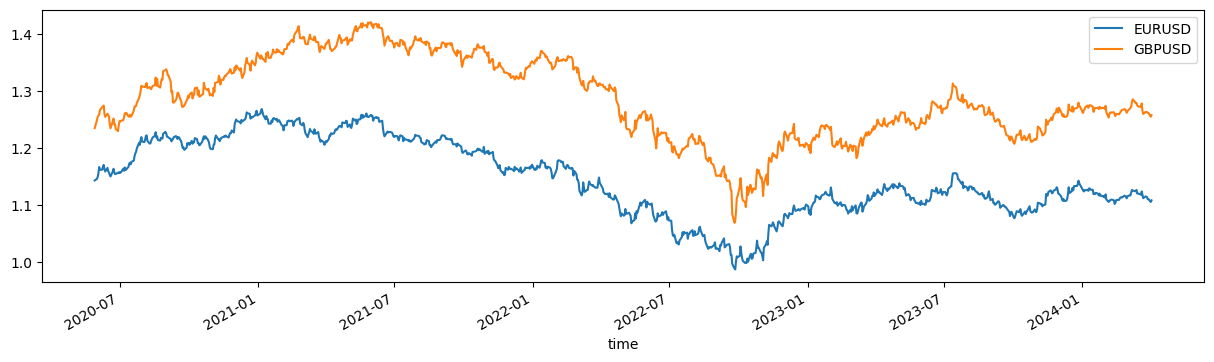

std: 0.02986554062490381


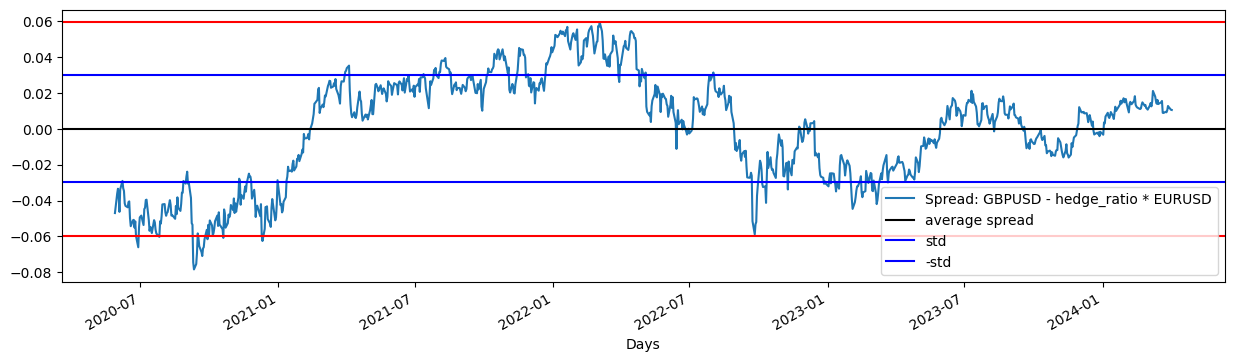

pvalue 0.218345154226 is > 0.05, assume spread is not stationary
EURUSD e GBPUSD NÃO são cointegrados.


In [71]:
#analisar_long_short(dfc,"BOVA11","WING21",1035,1)
#analisar_long_short(dfc,"PETR3" ,"CCRO3" ,1   ,2.4)
#analisar_long_short(dfc,"WDOH21","WING21",22.3,1)
#analisar_long_short(dfc,"HAPV3","CASH3",1.9,1)
#analisar_long_short(dfc,"MGLU3","CIEL3",1,6.15)
#analisar_long_short(dfc,"PETR4","BIDI4",1.70,1)
#analisar_long_short(dfc,"CIEL3","INDG21",29000,1)
#analisar_long_short(dfc,"CESP6","VVAR3",1,2.05)     #pvalor=0.009
#analisar_long_short(dfc,"INTB3","BRKM5",1.45,1)      #pvalor=0.005
#analisar_long_short(dfc,"ABEV3","RENT3",5,1)      #pvalor=0.005
#analisar_long_short(dfc,"HBSA3","MOVI3",4.24,1)      #pvalor=0.005
# analisar_long_short2("EURUSD","AUDUSD",2024,4,2,500,mt5.TIMEFRAME_D1)      #pvalor=0.005
# analisar_long_short2("EURUSD","USDCAD",2024,4,2,1000,mt5.TIMEFRAME_D1)      #pvalor=0.005
analisar_long_short2("EURUSD","GBPUSD",2024,4,2,1000,mt5.TIMEFRAME_D1)      #pvalor=0.005
